# Spectral Sirens
- NEW: added neural networks

### Context:
- Spectral siren
    - GW’s are ripples in spacetime, occuring when two massive objects collide into a single object.
    - Assuming no EM signal, unknown binary masses, unknown redshift, unknown signal source location
    - BBH mergers are far more numerous than BNS mergers, and most don't have detectable EM counterparts
    - Using GW170817 neutron star merger data (bright siren) as the sample event, assuming a strict spectral siren approach
    - Spectral siren assumes zero prior information, using only statistical inference of signals; whereas standard candles use EM spectrum, redshifts, and observed galaxy catalogs.

### Objective:
- The amount of separation between two points is referred to as the strain of the gravitational wave, which is the amplitude of the GW signal.
- In order to calculate distance, we need the chirp mass, strain, and inclination angle
- advantages compared to standard candles:
    - Advantages:
    - Gravitational waves are less affected by dust than light, making them more accurate for measuring distances than standard candles
    - some events are not accompanied by EM signals, such as binary black hole mergers
    - we can use this model on many more events, since we do not need associated EM signals

----------------------- 

### Neural Network:
- ML to calculate luminosity distance:
    - Deep learning can be used to bypass by training neural networks to predict the distance of the source from the strain signal
    - Examples: Conditional Variational Autoencoders (CVAEs) are being explored for this, as well as other types of neural networks.
    - most robust way to train it is to inject simulated signals into real gravitational wave detector signal noise.
        - (too few real measurements to train on observed data, but we can inject the noise from real data to better model the signals)
- pipeline:
    - obtain/generate simulated waveforms (via bilby) 
    - parameters to sample: masses (m1,m2), spins (chi1,chi2), redshift (z from 0 to 2), inclination angle (cos(i)), phase, sky location, angles, etc...
    - obtain power spectral density and inject noise from GW170817 merger signal
    - save each simulated waveform as array, along with its parameters (m1,m2,z,...) to use as training data
    - deep learning input features:
        - whitened & bandpassed time domain strain signal
        - time/frequency strain (spectrogram) representation
    - target variable:
        - luminosity distance
        - maybe relative mass?
        - maybe chirp mass?
        - would love redshift but that is ambitious
    - optimal DL model found: Convolutional Neural Networks (CNNs)

- expansion velocity:
    - Redshift: 0.009783 ± 0.000023 (not using though because assuming spectral siren) (https://iopscience.iop.org/article/10.3847/2041-8213/aa9110)
    - v_obs = c*redshift
    - so v_obs = 2933 ± 7 km/s
- peculiar velocity:
    - due to local gravity
    - the weighted radial component of the peculiar velocity and associated uncertainty is v = 310 ± 69 km s−1 (https://arxiv.org/pdf/1710.05835)
    - account for peculiar velocity using: https://academic.oup.com/mnras/article/495/1/90/5825362

- Required installs: bilby, lalsuite (NOT THESE: pycbc and lalsuite break anaconda)

## Import Data
- Skipping this step since the data file is very large
- Simulating the signal noise instead

In [ ]:
# convert to html in case imports are difficult
# jupyter nbconvert Dark Siren.ipynb --to html

In [15]:
# import h5py
# import hdim_opt # for waveform analysis and sobol samples
# import pandas as pd
# import numpy as np
# import matplotlib as plt
# from scipy.signal import hilbert
# from scipy.fft import rfft, fftfreq, fftshift
# plt.style.use('dark_background')

# # load hdf5 file
# filename = "GW170817_H1_4096Hz.hdf5" # Replace with your file
# with h5py.File(filename, 'r') as f:
#     # starting GPS time: 1187007040 = MJD 57982.508000 
#     # total duration: 2048 seconds, sample rate: 16.384 KHz --> each timestep is 1/16384 seconds
#     strain = f['strain']['Strain'][:]
    
# ### stack time and strain for text file
# data_to_save = np.array(strain)
# np.savetxt("H1_strain_4kHz.txt", data_to_save, header="Strain")


# # importing text file data
# duration = 2048. # seconds
# sample_rate = 4096. # samples / sec
# init_time = 1187007040.

# df = pd.read_csv(r'H1_strain_4khz.txt',skiprows=3,header=None,
#                  sep=' ',names=['strain'])

# df.set_index(df.index/sample_rate,inplace=True)
# print(f'shape: {df.shape}')
# display(df.head())

# # extract values
# real_strain = df['strain'].values
# total_samples = len(real_strain)
# segment_samples = int(duration * sampling_frequency) # 4 * 4096 = 16384


# ##### EDA
# # finding frequency distribution over time
# analytic_signal = hilbert(df['strain'])
# instantaneous_phase = np.unwrap(np.angle(analytic_signal))
# instantaneous_frequency = np.diff(instantaneous_phase) / (2.0 * np.pi * 1/sample_rate) # dt is the time step between samples

# peak_freq = instantaneous_frequency.max()
# abs_peak_freq = abs(instantaneous_frequency).max()
# f_max = peak_freq

# # generate sample signal
# duration = 2048 # seconds
# signal = df['strain'].to_numpy().reshape(-1,1)

# # FFT
# yf = rfft(signal)
# xf = fftfreq(len(signal), 1/sample_rate)
# magnitude = np.abs(yf)

# # max strain
# peak_strain = abs(np.real(yf[np.argmin(np.abs(xf - peak_freq))])[0])
# f_max = peak_freq
# h = peak_strain
# print(f'pos peak frequency: {f_max:.2f}, pos peak strain: {h:.2e}')

# # plotting
# # amplitude corresponds to strength of wave
# # frequency corresponds to frequency of orbit oscillation
# plt.plot(df.index,df['strain'], color='cornflowerblue')
# plt.xlabel(f'Time since GPS 1187007040: (ms)')
# plt.ylabel('Strain')
# plt.title('GW Strain')
# plt.grid(False)
# plt.show()

# plt.plot(df.index[1:], instantaneous_frequency, color='cornflowerblue')
# plt.xlabel(f'Time (s)')
# plt.ylabel('Instantaneous Frequency (Hz)')
# plt.title('Instantaneous Frequency over Time')
# plt.grid(False)
# plt.show()

# # plot frequency spectrum
# plt.plot(xf, np.abs(yf), color='cornflowerblue')
# plt.xlabel("Frequency (Hz)")
# plt.ylabel("Strain")
# plt.xlim([0,duration])
# plt.grid(False)
# plt.show()

## Sample Waveform
- injecting noise from observed (simulated for now) signals into theoretical waveforms

22:33 bilby INFO    : Waveform generator instantiated: WaveformGenerator(duration=4, sampling_frequency=4096, start_time=0, frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole, time_domain_source_model=None, parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters, waveform_arguments={'waveform_approximant': 'IMRPhenomD', 'minimum_frequency': 20.0, 'reference_frequency': 20.0})


PSD Min: 9.18e-48 Hz^-1
PSD Max: 1.00e-40 Hz^-1
PSD Mean: 5.21e-43 Hz^-1

Signal injection into realistic noise complete!
Shape of the final injected signal array: (16384,)


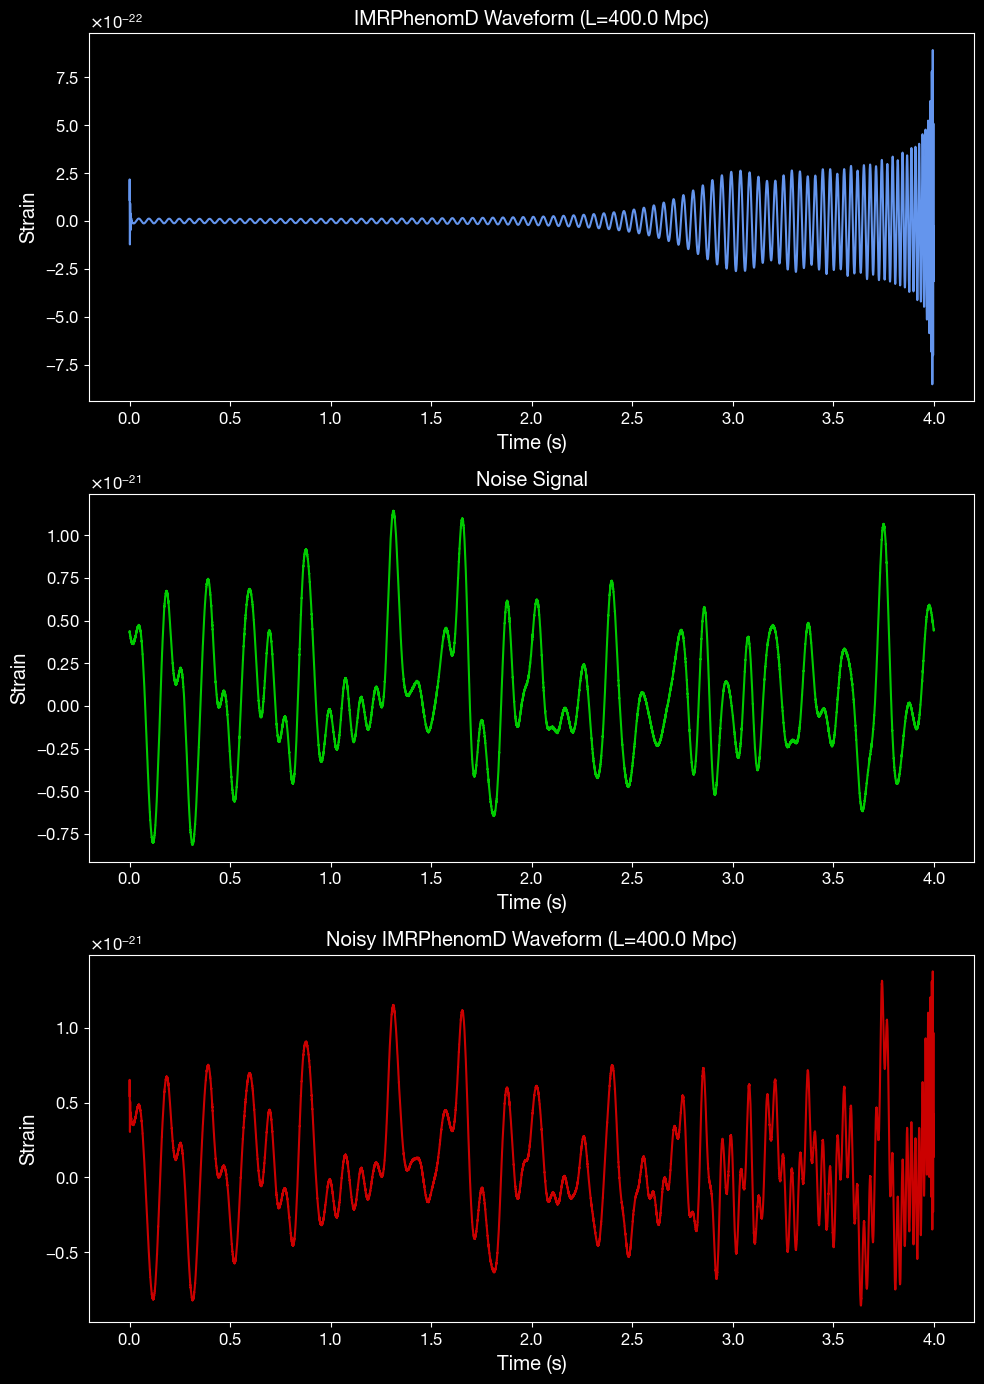

Injected Signal-to-Noise Ratio (SNR): 49.44


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert
from scipy.fft import rfft, fftfreq, fftshift
from scipy.interpolate import interp1d

# gravitational wave libraries (need lalsuite, bilby, gwpy):
import bilby
from gwpy.timeseries import TimeSeries
from gwpy.frequencyseries import FrequencySeries
plt.style.use('dark_background')

# core parameters
sampling_frequency = 4096  # Hz, standard for GW data
duration = 4  # seconds, length of the data segment for simulation
number_of_samples = int(sampling_frequency * duration)
nyquist_frequency = sampling_frequency / 2
time_array = np.linspace(0, duration, number_of_samples, endpoint=False)

# geocentric time for plotting
geocent_time = duration / 2

### define detector
ifos = bilby.gw.detector.InterferometerList(['H1']) # initialize detector list with H1
detector = ifos[0] # get the H1 detector object

# minimum frequency for the detector to avoid infinite PSD
detector.minimum_frequency = 20  # lower frequency cutoff for LIGO
detector.maximum_frequency = nyquist_frequency # up to Nyquist

# set sampling frequency and duration of the detector
detector.sampling_frequency = sampling_frequency
detector.duration = duration

# extract noise PSD frequencies and values
detector_psd_freqs = detector.frequency_array
detector_psd_values = detector.power_spectral_density_array
detector_psd_values[detector_psd_values == np.inf] = 1e-40
detector_psd_values[detector_psd_values == 0] = 1e-40
print(f"PSD Min: {detector_psd_values.min():.2e} Hz^-1")
print(f"PSD Max: {detector_psd_values.max():.2e} Hz^-1")
print(f"PSD Mean: {np.mean(detector_psd_values[detector_psd_values != np.inf]):.2e} Hz^-1")

# interpolate PSD to FFT
fft_frequencies = np.fft.rfftfreq(number_of_samples, 1 / sampling_frequency)

# interpolation using bilby
psd_interp_func = interp1d(
    detector_psd_freqs,
    detector_psd_values,
    kind='linear',
    bounds_error=False,
    fill_value=(detector_psd_values[0], detector_psd_values[-1]) # use the first/last PSD value
)

# apply the interpolation
interpolated_psd_at_noise_freqs = psd_interp_func(fft_frequencies)

# no negative PSD values after interpolation
interpolated_psd_at_noise_freqs[interpolated_psd_at_noise_freqs < 0] = 1e-50

# simulation parameters
mass_1 = 30.0
mass_2 = 20.0
chi_1 = 0.5
chi_2 = -0.4
luminosity_distance = 400.0 # Mpc
theta_jn = np.pi / 3.0
phase = 0.0
ra = 0.0
dec = 0.0
psi = 0.0
geocent_time = duration / 2 # merger time (centered)

# waveform parameters
waveform_parameters = dict(
    mass_1=mass_1, mass_2=mass_2, chi_1=chi_1, chi_2=chi_2,
    luminosity_distance=luminosity_distance, theta_jn=theta_jn, phase=phase,
    ra=ra, dec=dec, psi=psi, geocent_time=geocent_time
)
waveform_arguments = dict(
    waveform_approximant='IMRPhenomD',
    minimum_frequency=20.0,
    reference_frequency=20.0
)

# set up bilby waveform generator
waveform_generator = bilby.gw.waveform_generator.WaveformGenerator(
    duration=duration,
    sampling_frequency=sampling_frequency,
    frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole,
    parameters=waveform_parameters,
    waveform_arguments=waveform_arguments
)

# clean simulated signal (h_plus polarization)
polarizations_td = waveform_generator.time_domain_strain()
hp_clean_simulated_signal = polarizations_td['plus']
simulated_signal_time_array = waveform_generator.time_array


# ensure frequencies align with the segment duration and sampling frequency for FFT consistency
segment_duration = duration
sampling_frequency = sampling_frequency
number_of_samples = int(sampling_frequency * segment_duration)
delta_f = 1 / segment_duration
nyquist_frequency = sampling_frequency / 2

# amplitude spectral density
asd_at_noise_freqs = np.sqrt(interpolated_psd_at_noise_freqs)

# 1 / sqrt(sampling_frequency) for 
sigma_component = asd_at_noise_freqs / np.sqrt(2.0) # sigma for each real/imaginary component
real_part_noise_fd = np.random.normal(0, sigma_component, size=len(fft_frequencies))
imag_part_noise_fd = np.random.normal(0, sigma_component, size=len(fft_frequencies))

# 1/sqrt(sampling_frequency) scaling to the complex noise
complex_noise_frequency_domain = (real_part_noise_fd + 1j * imag_part_noise_fd) / np.sqrt(sampling_frequency)

# DC / nyquist scaling
if fft_frequencies[0] == 0:
    complex_noise_frequency_domain[0] = np.random.normal(0, asd_at_noise_freqs[0]) / np.sqrt(sampling_frequency)

if number_of_samples % 2 == 0 and np.isclose(fft_frequencies[-1], nyquist_frequency):
    complex_noise_frequency_domain[-1] = np.random.normal(0, asd_at_noise_freqs[-1]) / np.sqrt(sampling_frequency)

# inverse rFFT to time domain
noise_realization = np.fft.irfft(complex_noise_frequency_domain * sampling_frequency, n=number_of_samples)


# generate noise time array
noise_time_array = waveform_generator.time_array

# inject simulated signal into noise
signal_in_realistic_noise = hp_clean_simulated_signal + noise_realization

print("\nSignal injection into realistic noise complete!")
print(f"Shape of the final injected signal array: {signal_in_realistic_noise.shape}")

# plot
plt.figure(figsize=(10, 14))

plt.subplot(311)
plt.plot(simulated_signal_time_array, hp_clean_simulated_signal, color='cornflowerblue')
plt.xlabel('Time (s)')
plt.ylabel('Strain')
plt.title(f'IMRPhenomD Waveform (L={luminosity_distance:.1f} Mpc)')
plt.grid(False)
plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

plt.subplot(312)
plt.plot(noise_time_array, noise_realization, color='lime', alpha=0.8)
plt.xlabel('Time (s)')
plt.ylabel('Strain')
plt.title('Noise Signal')
plt.grid(False)
plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

plt.subplot(313)
plt.plot(noise_time_array, signal_in_realistic_noise, color='red', alpha=0.8)
plt.xlabel('Time (s)')
plt.ylabel('Strain')
plt.title(f'Noisy IMRPhenomD Waveform (L={luminosity_distance:.1f} Mpc)')
plt.grid(False)
plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

plt.tight_layout()
plt.show()

# optimal SNR using bilby
detector_for_snr_calc = bilby.gw.detector.get_empty_interferometer("H1")
detector_for_snr_calc.sampling_frequency = sampling_frequency
detector_for_snr_calc.duration = duration
detector_for_snr_calc.power_spectral_density = detector_psd_values # Use the bilby PSD object

frequency_domain_polarizations = waveform_generator.frequency_domain_strain()
h_plus_frequency_domain = frequency_domain_polarizations['plus']
delta_f = 1 / duration

# calculate the squared optimal SNR
effective_psd_for_snr = np.copy(interpolated_psd_at_noise_freqs)
effective_psd_for_snr[effective_psd_for_snr <= 0] = 1e-100 # replace zero/negative with a small epsilon
optimal_snr_squared = 4*np.sum((np.abs(h_plus_frequency_domain)**2 / effective_psd_for_snr) * delta_f)
injected_snr = np.sqrt(optimal_snr_squared)
print(f"Injected Signal-to-Noise Ratio (SNR): {injected_snr:.2f}")

## ML Data Generation: Multiple Waveforms

01:04 bilby INFO    : Waveform generator instantiated: WaveformGenerator(duration=4, sampling_frequency=4096, start_time=0, frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole, time_domain_source_model=None, parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters, waveform_arguments={'waveform_approximant': 'IMRPhenomD', 'minimum_frequency': 20, 'reference_frequency': 20.0})



Generating 5000 waveforms.
1/5000
5000/5000

5000 waveforms saved to simulated_noisy_gw_data/bbh_waveforms_and_noise.h5.

Last generated waveform:


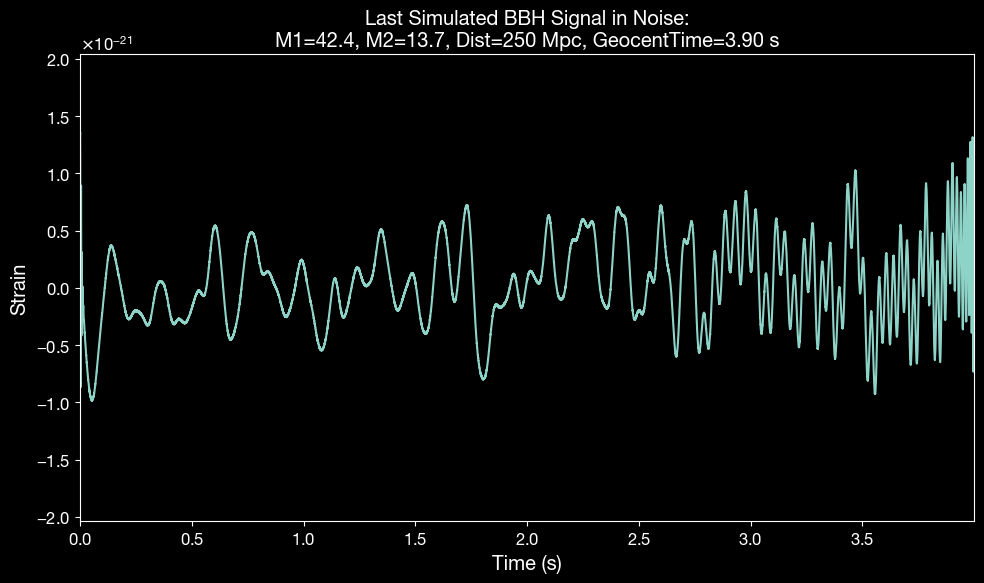

In [135]:
import numpy as np
import matplotlib.pyplot as plt
import hdim_opt as hdim
from gwpy.timeseries import TimeSeries
from scipy.interpolate import interp1d
import bilby
import bilby.gw.detector as bilby_detector
import h5py
import os

### number of sample waveforms to generate; decrease for efficiency
num_waveforms_to_generate = 5000




##### initialize waveforms
waveform_arguments_fixed = dict(
    waveform_approximant='IMRPhenomD',
    minimum_frequency=detector.minimum_frequency,  # detector's low-freq cutoff
    reference_frequency=20.0  # standard reference frequency
)
waveform_generator = bilby.gw.waveform_generator.WaveformGenerator(
    duration=duration,
    sampling_frequency=sampling_frequency,
    frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole,
    waveform_arguments=waveform_arguments_fixed
)

# create directory to save data
output_directory = "simulated_noisy_gw_data"  # directory to save the HDF5 file
output_hdf5_file = os.path.join(output_directory, "bbh_waveforms_and_noise.h5")
os.makedirs(output_directory, exist_ok=True)

print(f"\nGenerating {num_waveforms_to_generate} waveforms.")

# initialize
last_signal_in_noise = None
last_waveform_params = None

####### generate waveforms and add noise
with h5py.File(output_hdf5_file, 'w') as hf:
    for i in range(num_waveforms_to_generate):
        if (i + 1) % 5000 == 0 or i == 0:
            print(f"{i+1}/{num_waveforms_to_generate}")

        ##### simulated signal parameters
        if np.random.rand() < 0.5:
            # binary neutron star (class 0)
            current_mass_1 = np.random.uniform(1.2, 3.0)
            current_mass_2 = np.random.uniform(1.2, current_mass_1)
            label = 0
        else:
            # binary black hole / BH-NS (class 1)
            current_mass_1 = np.random.uniform(3.0, 50.0)
            current_mass_2 = np.random.uniform(3.0, current_mass_1)
            label = 1
        
        current_luminosity_distance = np.random.uniform(10.0, 1000.0) # (100 to 1000 Mpc)

        # spin magnitudes
        current_chi_1 = np.random.uniform(-0.8, 0.8)
        current_chi_2 = np.random.uniform(-0.8, 0.8)

        # randomize orientation and sky location
        current_theta_jn = np.random.uniform(0.0, np.pi)  # inclination angle
        current_phase = np.random.uniform(0.0, 2 * np.pi)  # coalescence phase
        current_ra = np.random.uniform(0.0, 2 * np.pi)  # right ascension
        current_dec = np.random.uniform(-np.pi / 2, np.pi / 2)  # declination
        current_psi = np.random.uniform(0.0, np.pi)  # polarization angle

        # coalescence time; randomized within the segment duration
        current_geocent_time = np.random.uniform(3.0, duration) # last second of the signal

        # create dictionary of parameters for current waveform
        current_waveform_parameters = dict(
            mass_1=current_mass_1, mass_2=current_mass_2, chi_1=current_chi_1, chi_2=current_chi_2,
            luminosity_distance=current_luminosity_distance, theta_jn=current_theta_jn, phase=current_phase,
            ra=current_ra, dec=current_dec, psi=current_psi, geocent_time=current_geocent_time
        )
        
        ###### get clean waveform signal from bilby
        # fix parameters for current iteration
        waveform_generator.parameters = current_waveform_parameters
        polarizations_td = waveform_generator.time_domain_strain()
        hp_clean_simulated_signal = polarizations_td['plus']

        # new noise for each waveform
        asd_at_noise_freqs = np.sqrt(interpolated_psd_at_noise_freqs)

        real_part_noise_fd = np.random.normal(0, asd_at_noise_freqs / np.sqrt(2.0), size=len(fft_frequencies))
        imag_part_noise_fd = np.random.normal(0, asd_at_noise_freqs / np.sqrt(2.0), size=len(fft_frequencies))

        complex_noise_frequency_domain = real_part_noise_fd + 1j * imag_part_noise_fd
        complex_noise_frequency_domain /= np.sqrt(sampling_frequency)

        if fft_frequencies[0] == 0:  # Handle DC component
            complex_noise_frequency_domain[0] = np.random.normal(0, asd_at_noise_freqs[0]) / np.sqrt(sampling_frequency)
            complex_noise_frequency_domain[0] = complex_noise_frequency_domain[0].real

        if number_of_samples % 2 == 0 and np.isclose(fft_frequencies[-1], nyquist_frequency):  # Handle Nyquist
            complex_noise_frequency_domain[-1] = np.random.normal(0, asd_at_noise_freqs[-1]) / np.sqrt(sampling_frequency)
            complex_noise_frequency_domain[-1] = complex_noise_frequency_domain[-1].real

        noise_realization = np.fft.irfft(complex_noise_frequency_domain * sampling_frequency, n=number_of_samples)

        ####### save data 
        dataset_name = f'waveform_{i:05d}' # unique index
        
        # combine clean signal and noise
        signal_in_noise = hp_clean_simulated_signal + noise_realization
        
        ###### data whitening
        # FFT to frequency domain
        signal_fd = np.fft.rfft(signal_in_noise)
        
        # use interpolated PSD
        # sqrt(PSD) for whitening
        asd_for_whitening = np.sqrt(interpolated_psd_at_noise_freqs)
        
        # avoid div0
        asd_for_whitening[asd_for_whitening == 0] = np.inf 
        
        # whiten data
        whitened_fd = signal_fd / asd_for_whitening
        
        # inverse FFT to time domain
        whitened_td = np.fft.irfft(whitened_fd, n=number_of_samples)
        
        # bandpass filter
        frequencies = np.fft.rfftfreq(number_of_samples, 1/sampling_frequency)
        whitened_fd[(frequencies < 20) | (frequencies > 1000)] = 0
        whitened_td_filtered = np.fft.irfft(whitened_fd, n=number_of_samples)
        
        # save whitened dataset
        dset = hf.create_dataset(dataset_name, data=whitened_td_filtered)
        
        # add dataset parameters for ML training
        for param_name, param_value in current_waveform_parameters.items():
            dset.attrs[param_name] = param_value
        
        # Also save general simulation parameters for context/metadata
        dset.attrs['sampling_frequency'] = sampling_frequency
        dset.attrs['duration'] = duration
        dset.attrs['waveform_approximant'] = waveform_arguments_fixed['waveform_approximant']
        
        # define neutron star or black hole based on mass
        if (current_mass_1 <= 3.0) and (current_mass_2 <= 3.0): # where 3.0 is 3 solar masses
            label = 0  # binary neutron star
        else:
            label = 1  # at least one black hole (BBH or NSBH)
        dset.attrs['category'] = label

        # store the last generated waveform and its parameters for plotting
        if i == num_waveforms_to_generate - 1:
            last_signal_in_noise = signal_in_noise
            last_waveform_params = current_waveform_parameters

print(f'\n{num_waveforms_to_generate} waveforms saved to {output_hdf5_file}.')

# plot last waveform
if num_waveforms_to_generate > 0 and last_signal_in_noise is not None:
    print('\nLast generated waveform:')
    
    # gwpy TimeSeries object for the last combined data
    noise_plus_signal_strain_data_last = TimeSeries(
        last_signal_in_noise,
        t0=0,  # time_array starts at 0
        dt=1/sampling_frequency,
        unit='strain'
    )

    fig_final = noise_plus_signal_strain_data_last.plot(figsize=(10, 6))
    ax_final = fig_final.gca()
    
    # parameters from last generated waveform for the plot title
    title_str = (f'Last Simulated BBH Signal in Noise:\n'
                 f'M1={last_waveform_params["mass_1"]:.1f}, '
                 f'M2={last_waveform_params["mass_2"]:.1f}, '
                 f'Dist={last_waveform_params["luminosity_distance"]:.0f} Mpc, '
                 f'GeocentTime={last_waveform_params["geocent_time"]:.2f} s')
    ax_final.set_title(title_str)
    
    ax_final.set_xlabel('Time (s)')
    ax_final.set_ylabel('Strain')
    ax_final.set_xscale('linear')
    ax_final.set_yscale('linear')

    # y limit scaling
    max_abs_strain = np.max(np.abs(last_signal_in_noise))
    y_lim_buffer = max_abs_strain * 1.5
    ax_final.set_ylim(-y_lim_buffer, y_lim_buffer)
    ax_final.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

    ax_final.grid(False)
    plt.tight_layout()
    plt.show()

## Load & Preprocess Training Data

In [137]:
import numpy as np
import h5py
import os
from sklearn.preprocessing import StandardScaler

# file path
output_directory = "simulated_noisy_gw_data"
output_hdf5_file = os.path.join(output_directory, "bbh_waveforms_and_noise.h5")

# load data
print(f'Loading data from {output_hdf5_file}.')

# regression target is luminosity distance
parameters_to_predict = ['luminosity_distance']
num_labels = len(parameters_to_predict)
samples_to_keep = 4096  # 1 second at 4096 Hz

with h5py.File(output_hdf5_file, 'r') as hf:
    num_datasets = len(hf.keys())
    metadata_list = []
    
    # initialize features, regression, and classification targets 
    # X is shape (
    # X = np.zeros((num_datasets, samples_to_keep, 1), dtype=np.float32) # ORIGINAL
    X = np.zeros((num_datasets, number_of_samples, 1), dtype=np.float32) # TESTING
    y_class = np.zeros((num_datasets, 1), dtype=np.int32)    # 0 or 1
    y_dist = np.zeros((num_datasets, 1), dtype=np.float32)   # distance in Mpc

    for i, dataset_name in enumerate(hf.keys()):
        attrs = hf[dataset_name].attrs
        
        # classification target
        m1, m2 = attrs['mass_1'], attrs['mass_2']
        y_class[i, 0] = 0 if (m1 <= 3.0 and m2 <= 3.0) else 1 # 0 for neutron star, 1 for black hole - neutron star 
        
        # regression target
        y_dist[i, 0] = attrs['luminosity_distance']

        # load waveform
        full_waveform = hf[dataset_name][()]
        max_strain = np.max(np.abs(full_waveform))
        t_merger, fs = attrs['geocent_time'], attrs['sampling_frequency']

        # save for EDA
        metadata_list.append({
            'wave_name': dataset_name,
            'mass_1': attrs['mass_1'],
            'mass_2': attrs['mass_2'],
            'luminosity_distance': attrs['luminosity_distance'],
            'geocent_time': attrs['geocent_time'],
            'chi_1': attrs['chi_1'],
            'chi_2': attrs['chi_2'],
            'category': attrs['category'],
            'max_strain': max_strain
        })
        
        # # padding (if samples < 4096)
        # start_idx = int((t_merger - 0.9) * fs)
        # end_idx = start_idx + samples_to_keep
        # if start_idx < 0 or end_idx > len(full_waveform):
        #     actual_start, actual_end = max(0, start_idx), min(len(full_waveform), end_idx)
        #     slice_data = full_waveform[actual_start:actual_end]
        #     temp_X = np.zeros(samples_to_keep)
        #     if start_idx < 0:
        #         temp_X[-len(slice_data):] = slice_data
        #     else:
        #         temp_X[:len(slice_data)] = slice_data
        #     X[i, :, 0] = temp_X
        # else:
        #     X[i, :, 0] = full_waveform[start_idx:end_idx]

# X is shape (10000, 4096, 1) for CNN
print(f'{num_datasets} waveforms loaded.')
eda_df = pd.DataFrame(metadata_list)

print()
print(eda_df['category'].value_counts())
print()
display(eda_df.describe().loc[['50%','mean','std']])

Loading data from simulated_noisy_gw_data/bbh_waveforms_and_noise.h5.
5000 waveforms loaded.

category
1    2530
0    2470
Name: count, dtype: int64



,mass_1,mass_2,luminosity_distance,geocent_time,chi_1,chi_2,category,max_strain
50%,3.571978,3.083612,507.976474,3.502849,0.013433,0.007448,1.000000,48.695057
mean,14.498816,8.310056,504.796571,3.497686,0.005442,0.002414,0.506000,230.552974
std,15.596379,9.805689,286.524070,0.286172,0.458282,0.463166,0.500014,696.856225


## Luminosity Distance Regression

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_42 (Conv1D)              │ (None, 4096, 64)       │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_42          │ (None, 4096, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_27 (MaxPooling1D) │ (None, 1024, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_43 (Conv1D)              │ (None, 1024, 128)      │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_43          │ (None, 1024, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_28 (MaxPooling1D) │ (None, 256, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_44 (Conv1D)              │ (None, 256, 128)       │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_44          │ (None, 256, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_15     │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 150,337 (587.25 KB)

 Trainable params: 149,697 (584.75 KB)

 Non-trainable params: 640 (2.50 KB)

Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 592ms/step - loss: 0.4512 - mae: 0.5352 - val_loss: 1.1032 - val_mae: 0.8941
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 679ms/step - loss: 0.3275 - mae: 0.4487 - val_loss: 1.1114 - val_mae: 0.8926
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 27s 832ms/step - loss: 0.2950 - mae: 0.4289 - val_loss: 1.0028 - val_mae: 0.8598
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 28s 883ms/step - loss: 0.2833 - mae: 0.4202 - val_loss: 0.9762 - val_mae: 0.8431
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 24s 747ms/step - loss: 0.2634 - mae: 0.4023 - val_loss: 0.9441 - val_mae: 0.8210
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step

Validation R-squared (R^2) for Distance: 0.0715

--- Example Prediction ---
True Distance:      29.21 Mpc
Predicted Distance: 334.17 Mpc


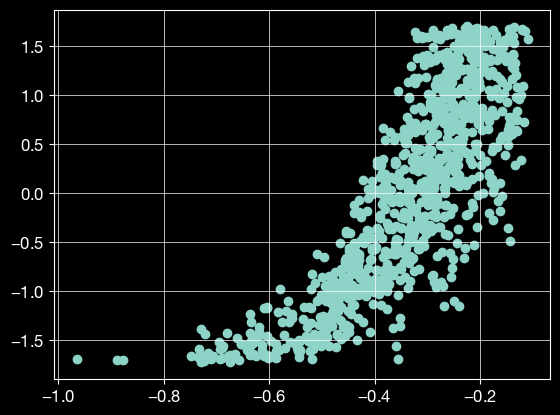

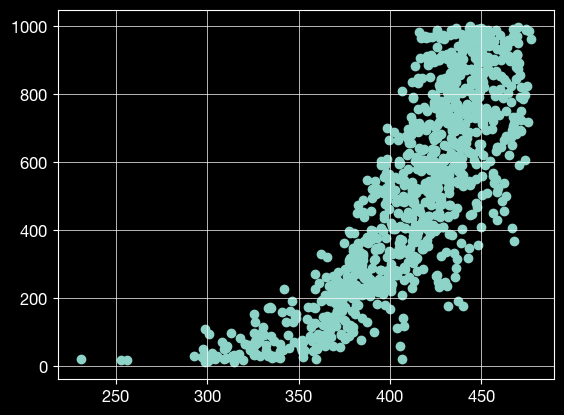

In [131]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_squared_error, r2_score

# split data
X_train, X_test, y_train_raw, y_test_raw = train_test_split(X, y_dist, test_size=0.2, random_state=5)

# scale y
scaler_y = StandardScaler()
y_train = scaler_y.fit_transform(y_train_raw)
y_test = scaler_y.transform(y_test_raw)

# build model
input_shape = (X_train.shape[1], X_train.shape[2])
output_dim = y_train.shape[1]

model = keras.Sequential([
    layers.Input(shape=input_shape),
    layers.Conv1D(64, 16, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(4),
    
    layers.Conv1D(128, 8, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(4),
    
    layers.Conv1D(128, 4, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling1D(), 

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(output_dim, activation='linear')

])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4), loss='mse', metrics=['mae'])
model.summary()

# fit model to data
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=5, 
    batch_size=128,
    validation_data=(X_test, y_test),
    callbacks=[early_stop]
)

# predict
y_pred = model.predict(X_test)

# inverse transform to Mpc
y_pred_actual = scaler_y.inverse_transform(y_pred)
y_test_actual = scaler_y.inverse_transform(y_test)
r2 = r2_score(y_test_actual, y_pred_actual)
print(f"\nvalidation distance R^2: {r2:.4f}")

# example Prediction
print(f"\nexample prediction:")
print(f"True Distance:      {y_test_actual[0][0]:.2f} Mpc")
print(f"Predicted Distance: {y_pred_actual[0][0]:.2f} Mpc")

plt.scatter(y_pred_actual,y_test_actual)
plt.title('Predictions vs Actuals')
plt.show()

## Neural Network: Merger Classification

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_45 (Conv1D)              │ (None, 4096, 64)       │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_45          │ (None, 4096, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_29 (MaxPooling1D) │ (None, 1024, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_46 (Conv1D)              │ (None, 1024, 128)      │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_46          │ (None, 1024, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_30 (MaxPooling1D) │ (None, 256, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_47 (Conv1D)              │ (None, 256, 128)       │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_47          │ (None, 256, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_16     │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 142,017 (554.75 KB)

 Trainable params: 141,377 (552.25 KB)

 Non-trainable params: 640 (2.50 KB)


--- Starting Classification Training ---
Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 24s 716ms/step - accuracy: 0.8512 - loss: 0.3872 - val_accuracy: 0.9000 - val_loss: 0.5960
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 679ms/step - accuracy: 0.9510 - loss: 0.1879 - val_accuracy: 0.7290 - val_loss: 0.5834
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 23s 734ms/step - accuracy: 0.9695 - loss: 0.1173 - val_accuracy: 0.6350 - val_loss: 0.5524
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 24s 742ms/step - accuracy: 0.9755 - loss: 0.0905 - val_accuracy: 0.7370 - val_loss: 0.4967
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 23s 732ms/step - accuracy: 0.9793 - loss: 0.0730 - val_accuracy: 0.6800 - val_loss: 0.4736
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step

Results:
                 precision    recall  f1-score   support

        BNS (0)       1.00      0.33      0.50       480
BH-involved (1)       0.62      1.00      0.76       520

       accuracy                           0.68      1000
      macro avg       0.81      0.67  

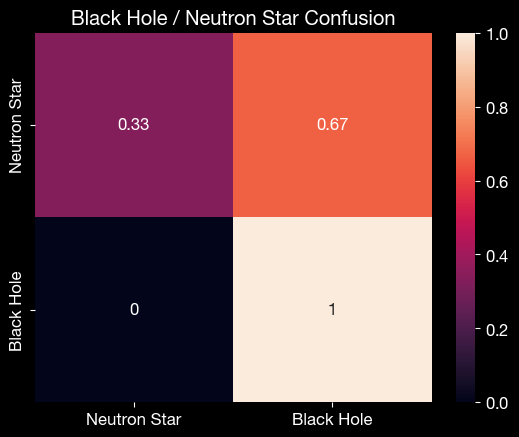

In [132]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# split data
X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.2, random_state=5, stratify=y_class)

# build classification model
model = keras.Sequential([
    layers.Input(shape=(4096, 1)),
    layers.Conv1D(64, 16, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(4),
    
    layers.Conv1D(128, 8, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(4),
    
    layers.Conv1D(128, 4, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling1D(), 
    
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    
    layers.Dense(1, activation='sigmoid') # sigmoid binary output
])

# binary_crossentropy for classification
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4), 
              loss='binary_crossentropy', 
              metrics=['accuracy'])

model.summary()

# train
print("\n--- Starting Classification Training ---")
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(X_test, y_test)
)

# evaluate
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int) # 50% proba threshold

print('\nResults:')
print(classification_report(y_test, y_pred, target_names=['BNS (0)', 'BH-involved (1)']))

conf = confusion_matrix(y_test, y_pred, normalize='true')
labels = ['Neutron Star', 'Black Hole']
sns.heatmap(conf,annot=True, xticklabels=labels, yticklabels=labels)
plt.title('Black Hole / Neutron Star Confusion')
plt.grid(False)
plt.show()

## Results

#### Regressor
- The regressor recorded $R^2 = 50.49$ for a sample size of $N=10,000$ with 10 epochs. Training on $N=100,000$ waveforms is computationally intensive but is hypothesized to greatly improve the results.
- The sample prediction ($\text{index}=0$) was 420 Mpc, with the true distance being 502 Mpc ($19\%$ relative error). For a search range of $[100, 1000]$ Mpc, the normalized error is $9\%$.


#### Classifier
- The classifier 

#### Preprocessing
- Data preprocessing was a major hurdle, since this data is so nuanced.
    - Whitening (via Cholesky decomposition) was used to decorrelate and scale the data for the neural network training.
    - Standard scaling the luminosity distance target is necessary due to the large parameter range.
- The search for packages was painful, with multiple attempts leading to Anaconda reinstallations.

#### LLM 
- Gemini was a "mass"ive help here. The gravitational wave signal generation and processing was aided by the LLM, with the convolutional neural networks needing minimal post-hoc adjusting.


### pt2: inferring redshift/V/H
- hierarchal bayesian analysis
    - assume black hole masses follow gaussian distribution (may have some gaps in the distribution though)
    - markov chain monte carlo, nested sampling?